*© Sabrine Bendimerad · [sbendimerad.github.io](https://sbendimerad.github.io) · Licence [CC BY-NC-SA 4.0](https://creativecommons.org/licenses/by-nc-sa/4.0/): you may share and adapt this material with credit, for non-commercial use, under the same licence. Datasets keep their own licences.*

# Fraudulent activities 🕵️

## Objective
E-commerce websites handle a lot of money, which creates a real risk of fraud: stolen credit cards, money laundering... Fortunately, machine learning can help: every website where you enter your payment details has a team that manages the risk of fraud, often with ML models.

The goal of this exercise is to build a model that predicts whether a transaction is fraudulent.

## Description
Company X sells handmade clothes online. You must build a model that predicts whether the purchase of a piece of clothing should be considered a fraudulent transaction. Here is what you have to do:

1. For each user, find the country from their IP address.
2. Build a model that predicts whether an activity is fraudulent. Explain your choices regarding false positives and false negatives.
3. Your boss is worried about using a *black box* model: how would you explain your model from a user's point of view, not a mathematical one? For instance, which users can be considered *risky*?
4. Suppose the model can make its predictions live, in real time. From a product point of view, how would you use it? What would the user experience be?

## Data
* `data/fraud_data.csv`: one row per user and their first purchase. `class` is the target (1 = fraud).
* `data/ip_address_to_country.csv`: IP address ranges (`lower_bound_ip_address`, `upper_bound_ip_address`) and their country.

In [ ]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.naive_bayes import GaussianNB
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, precision_score, recall_score, ConfusionMatrixDisplay

import plotly.io as pio
import plotly.graph_objects as go
# colour palette of the course
pio.templates["course"] = go.layout.Template(
    layout_colorway=["#3B47C4", "#E4572E", "#2E7D4F", "#F2C14E", "#8E7CC3", "#4BA3C3", "#111111", "#999999"]
)
pio.templates.default = "plotly_white+course"

## Load the data

In [ ]:
fraud = pd.read_csv("data/fraud_data.csv")
ip_country = pd.read_csv("data/ip_address_to_country.csv")
print(fraud.shape, ip_country.shape)
print(f"Fraud rate: {fraud['class'].mean():.1%}")
fraud.head()

(151112, 11) (138846, 3)
Fraud rate: 9.4%


,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,age,ip_address,class
0,22058,2015-02-24 22:55:49,2015-04-18 02:47:11,34,QVPSPJUOCKZAR,SEO,Chrome,M,39,7.327584e+08,0
1,333320,2015-06-07 20:39:50,2015-06-08 01:38:54,16,EOGFQPIZPYXFZ,Ads,Chrome,F,53,3.503114e+08,0
2,1359,2015-01-01 18:52:44,2015-01-01 18:52:45,15,YSSKYOSJHPPLJ,SEO,Opera,M,53,2.621474e+09,1
3,150084,2015-04-28 21:13:25,2015-05-04 13:54:50,44,ATGTXKYKUDUQN,SEO,Safari,M,41,3.840542e+09,0
4,221365,2015-07-21 07:09:52,2015-09-09 18:40:53,39,NAUITBZFJKHWW,Ads,Safari,M,45,4.155831e+08,0


## 1. Country of each user
For each user, we must find the IP range that contains their address. Looping over the users (`apply` with a filter on the whole table for each row) works, but it scans 138,000 ranges for each of the 151,000 users: it takes hours!

💡 `pd.merge_asof` does this kind of lookup in a fraction of a second: for each IP address, it finds the last range that starts before it (both tables must be sorted). Then check that the address is not beyond the end of that range.

In [ ]:
fraud = fraud.sort_values("ip_address")
ip_country = ip_country.sort_values("lower_bound_ip_address")

fraud = pd.merge_asof(fraud, ip_country, left_on="ip_address", right_on="lower_bound_ip_address", direction="backward")
outside = fraud["ip_address"] > fraud["upper_bound_ip_address"]       # not inside the range found
fraud.loc[outside, "country"] = np.nan
fraud["country"] = fraud["country"].fillna("Unknown")
fraud = fraud.drop(columns=["lower_bound_ip_address", "upper_bound_ip_address"])

fraud["country"].value_counts().head(10)

country
United States        58049
Unknown              21966
China                12038
Japan                 7306
United Kingdom        4490
Korea Republic of     4162
Germany               3646
France                3161
Canada                2975
Brazil                2961
Name: count, dtype: int64

## 2. Feature engineering
Some columns can't be used as they are: dates, device identifiers, IP addresses. But they hide very useful information. Create:
* `seconds_to_purchase`: the time between the sign-up and the purchase, in seconds;
* `users_per_device`: the number of users who used the same device;
* `users_per_ip`: the number of users who used the same IP address;
* `purchase_hour` and `purchase_weekday`;
* `country_group`: the country for the 20 most frequent countries, `Other` for the others.

In [ ]:
for col in ["signup_time", "purchase_time"]:
    fraud[col] = pd.to_datetime(fraud[col])

fraud["seconds_to_purchase"] = (fraud["purchase_time"] - fraud["signup_time"]).dt.total_seconds()
fraud["users_per_device"] = fraud.groupby("device_id")["user_id"].transform("count")
fraud["users_per_ip"] = fraud.groupby("ip_address")["user_id"].transform("count")
fraud["purchase_hour"] = fraud["purchase_time"].dt.hour
fraud["purchase_weekday"] = fraud["purchase_time"].dt.day_of_week

top_countries = fraud["country"].value_counts().index[:20]
fraud["country_group"] = fraud["country"].where(fraud["country"].isin(top_countries), "Other")
fraud.head()

,user_id,signup_time,purchase_time,purchase_value,device_id,source,browser,sex,age,ip_address,class,country,seconds_to_purchase,users_per_device,users_per_ip,purchase_hour,purchase_weekday,country_group
0,62421,2015-02-16 00:17:05,2015-03-08 10:00:39,46,ZCLZTAJPCRAQX,Direct,Safari,M,36,52093.496895,0,Unknown,1763014.0,1,1,10,6,Unknown
1,173212,2015-03-08 04:03:22,2015-03-20 17:23:45,33,YFGYOALADBHLT,Ads,IE,F,30,93447.138961,0,Unknown,1084823.0,1,1,17,4,Unknown
2,242286,2015-05-17 16:45:54,2015-05-26 08:54:34,33,QZNVQTUITFTHH,Direct,FireFox,F,32,105818.501505,0,Unknown,749320.0,1,1,8,1,Unknown
3,370003,2015-03-03 19:58:39,2015-05-28 21:09:13,33,PIBUQMBIELMMG,Ads,IE,M,40,117566.664867,0,Unknown,7434634.0,1,1,21,3,Unknown
4,119824,2015-03-20 00:31:27,2015-04-05 07:31:46,55,WFIIFCPIOGMHT,Ads,Safari,M,38,131423.789042,0,Unknown,1407619.0,1,1,7,6,Unknown


3. Compare the fraud rate for purchases made within one second of the sign-up and the others. Then plot the fraud rate as a function of `users_per_device`. What do you see?

In [ ]:
quick = fraud["seconds_to_purchase"] <= 1
print(f"Purchases within 1 second of the sign-up: {quick.sum()} rows, fraud rate {fraud.loc[quick, 'class'].mean():.0%}")
print(f"Other purchases: {(~quick).sum()} rows, fraud rate {fraud.loc[~quick, 'class'].mean():.1%}")

rate = fraud.groupby(fraud["users_per_device"].clip(upper=10))["class"].agg(["mean", "size"]).reset_index()
fig = px.bar(rate, x="users_per_device", y="mean", hover_data=["size"],
             labels={"users_per_device": "users of the same device (10 = 10 or more)", "mean": "fraud rate"},
             title="Fraud rate vs. number of users of the same device")
fig.show()

Purchases within 1 second of the sign-up: 7600 rows, fraud rate 100%
Other purchases: 143512 rows, fraud rate 4.6%


**Every purchase made within one second of the sign-up is a fraud: no human creates an account and pays that fast, these are bots. And when several accounts share the same device, the fraud rate rises quickly: above 5 users per device, most purchases are frauds.**

## 3. Models
Split the data (stratified, 20% for the test set), then compare:
1. a **Gaussian Naive Bayes** using only the raw numeric columns `purchase_value`, `age` and `purchase_hour`;
2. the same model with the **engineered numeric features**;
3. a **logistic regression** and a **random forest** with all the features (one-hot encode the categorical ones).

The fraud class is the minority: use the F1-score, the precision and the recall.

In [ ]:
numeric = ["purchase_value", "age", "seconds_to_purchase", "users_per_device", "users_per_ip", "purchase_hour", "purchase_weekday"]
categorical = ["source", "browser", "sex", "country_group"]
X, y = fraud[numeric + categorical], fraud["class"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=0)


def evaluate(name, model, num_cols, cat_cols=()):
    """Train a pipeline (scaling + one-hot encoding + model) and print its scores on the test set."""
    steps = [("num", StandardScaler(), list(num_cols))]
    if cat_cols:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), list(cat_cols)))
    pipeline = Pipeline([("preprocessing", ColumnTransformer(steps)), ("model", model)])
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)
    print(f"{name:40} F1 {f1_score(y_test, y_pred):.3f}   precision {precision_score(y_test, y_pred, zero_division=0):.3f}"
          f"   recall {recall_score(y_test, y_pred):.3f}")
    return pipeline


evaluate("Naive Bayes, raw numeric columns", GaussianNB(), ["purchase_value", "age", "purchase_hour"])
evaluate("Naive Bayes, engineered features", GaussianNB(), numeric)
evaluate("Logistic regression, all features", LogisticRegression(max_iter=2000), numeric, categorical)
forest = evaluate("Random forest, all features",
                  RandomForestClassifier(n_estimators=100, max_depth=8, n_jobs=-1, random_state=0), numeric, categorical)

Naive Bayes, raw numeric columns         F1 0.000   precision 0.000   recall 0.000
Naive Bayes, engineered features         F1 0.681   precision 0.932   recall 0.537


Logistic regression, all features        F1 0.671   precision 0.930   recall 0.525


Random forest, all features              F1 0.696   precision 1.000   recall 0.533


**On the raw columns, Naive Bayes finds no fraud at all: the purchase value, the age or the hour say nothing about fraud. With the engineered features, the same model becomes good. The random forest is only a little better: here, the features make the difference much more than the choice of the model.**

## 4. False positives and false negatives
* A **false positive** is a legitimate customer flagged as a fraud: an angry customer, maybe a lost sale.
* A **false negative** is a fraud that goes through: the company loses the money.

Plot the confusion matrix of your best model. Then use `predict_proba` to see how the precision and the recall change with the decision threshold. Which threshold would you choose?

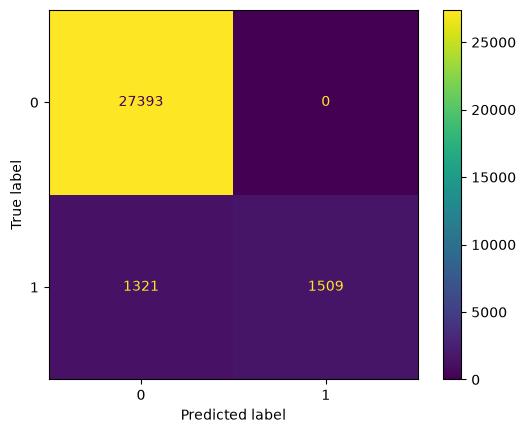

In [ ]:
ConfusionMatrixDisplay.from_estimator(forest, X_test, y_test);

In [ ]:
proba = forest.predict_proba(X_test)[:, 1]
rows = []
for threshold in [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    y_pred = (proba >= threshold).astype(int)
    rows.append({"threshold": threshold, "precision": precision_score(y_test, y_pred), "recall": recall_score(y_test, y_pred),
                 "frauds caught": int((y_pred & y_test.to_numpy()).sum()), "false alerts": int((y_pred & (1 - y_test.to_numpy())).sum())})
pd.DataFrame(rows).round(3)

,threshold,precision,recall,frauds caught,false alerts
0,0.1,0.534,0.719,2035,1779
1,0.2,0.834,0.586,1658,329
2,0.3,0.988,0.534,1511,19
3,0.4,1.000,0.533,1509,0
4,0.5,1.000,0.533,1509,0
5,0.6,1.000,0.533,1509,0
6,0.7,1.000,0.533,1509,0
7,0.8,1.000,0.533,1509,0


**With the default threshold, the model makes no false alerts but catches only about half of the frauds: the obvious ones (bots, shared devices). Lowering the threshold catches a few more frauds, but the false alerts grow much faster. The other frauds look like normal purchases with these features.**

**The right threshold depends on the costs: if a fraud costs much more than an extra check, accept more false alerts, but handle them with a soft check rather than a blocked payment (see question 4).**

## 5. Explaining the model to your boss
Plot the feature importances of the random forest. Which users are risky?

In [ ]:
names = forest.named_steps["preprocessing"].get_feature_names_out()
importances = pd.Series(forest.named_steps["model"].feature_importances_, index=names).sort_values().tail(12)
fig = px.bar(x=importances.values, y=importances.index, orientation="h", title="Random forest: feature importances",
             labels={"x": "importance", "y": ""})
fig.show()

**The model relies almost only on two signals, easy to explain without maths:**
* **an account created and used within a second**: no human is that fast, this is a bot;
* **several accounts on the same device or IP address**: one person creating many accounts, typically to use stolen cards.

**Risky users are new accounts that buy immediately after signing up, from a device or an address already used by other accounts. The other features (country, browser, age, amount) bring very little.**

## 6. Using the model live
**The model can score each purchase in real time, before the payment is accepted. Rather than a yes/no decision, use the probability to adapt the experience:**
* **low risk** (most customers): the payment goes through, no friction;
* **medium risk**: ask for an extra check (a code sent by SMS, a 3-D Secure confirmation from the bank);
* **high risk**: hold the order for a manual review by the fraud team before shipping.

**This keeps the experience smooth for legitimate customers, and makes fraud harder. The model must then be monitored: fraudsters adapt (for instance, bots will wait a few seconds before buying), so it needs to be retrained regularly with the new cases.**